In [2]:
import zipfile
import os

zip_path = '/content/' + next(
    f for f in os.listdir('/content') if f.endswith('.zip')
)

os.makedirs('/content/loan_data', exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall('/content/loan_data')

print("Extracted files:")
print(os.listdir('/content/loan_data'))

Extracted files:
['loan_prediction.csv']


In [3]:

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

# Find the CSV inside the extracted dataset folder
csv_files = glob.glob('/content/loan_data/**/*.csv', recursive=True)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Check the files extracted in /content/loan_data."
    )

print("CSV files found:")
for i, file in enumerate(csv_files):
    print(i, file)

df = pd.read_csv(csv_files[0])

# Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

print("\nDataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())


CSV files found:
0 /content/loan_data/loan_prediction.csv

Dataset shape: (614, 13)


,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Columns: ['loan_id', 'gender', 'married', 'dependents', 'education', 'self_employed', 'applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'property_area', 'loan_status']


In [4]:

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Find the loan approval target column
target_candidates = [
    c for c in df.columns
    if c.replace('_', '') in ['loanstatus', 'loanapprovalstatus']
]

if not target_candidates:
    raise ValueError(
        "Target column not found. Check the column names printed in Cell 1."
    )

target = target_candidates[0]

# Standardize target labels
df[target] = df[target].astype(str).str.strip().str.lower()

target_mapping = {
    'approved': 1, 'approve': 1, 'yes': 1, 'y': 1, '1': 1, '1.0': 1,
    'rejected': 0, 'reject': 0, 'no': 0, 'n': 0, '0': 0, '0.0': 0
}

df[target] = df[target].map(target_mapping)
df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(int)

print("Target column:", target)
print("\nTarget distribution:")
print(df[target].value_counts())
print("\nTarget proportions:")
print(df[target].value_counts(normalize=True).round(3))


Missing values before cleaning:
loan_id               0
gender               13
married               3
dependents           15
education             0
self_employed        32
applicantincome       0
coapplicantincome     0
loanamount           22
loan_amount_term     14
credit_history       50
property_area         0
loan_status           0
dtype: int64

Duplicate rows: 0
Target column: loan_status

Target distribution:
loan_status
1    422
0    192
Name: count, dtype: int64

Target proportions:
loan_status
1    0.687
0    0.313
Name: proportion, dtype: float64


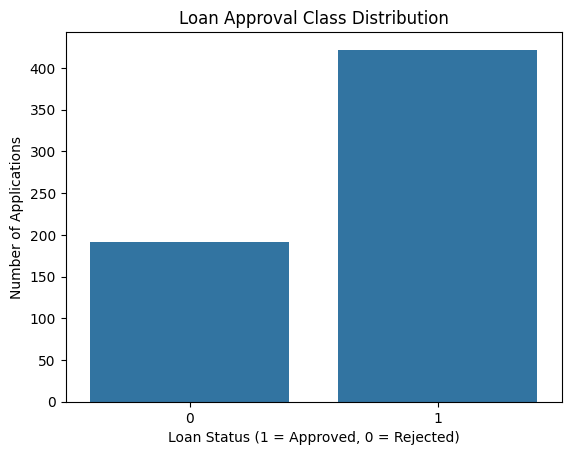

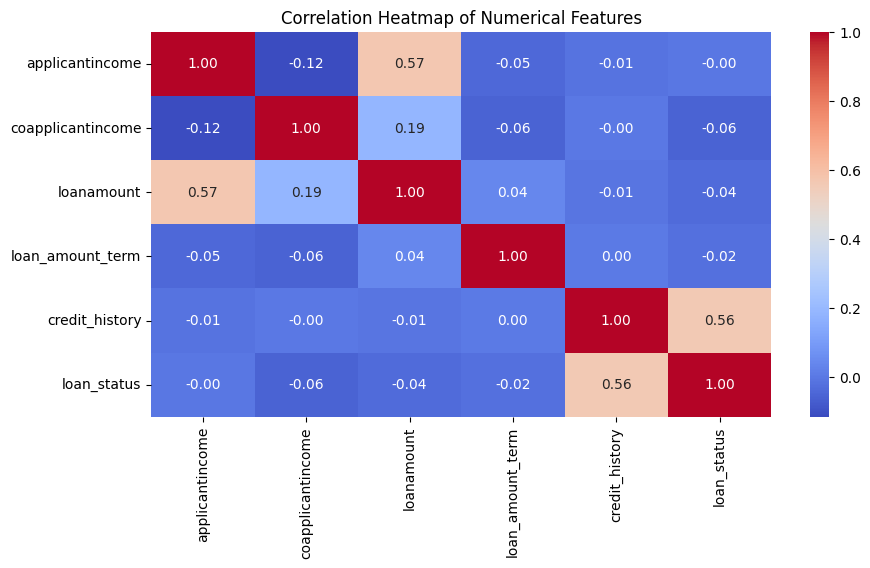

In [5]:

sns.countplot(data=df, x=target)
plt.title("Loan Approval Class Distribution")
plt.xlabel("Loan Status (1 = Approved, 0 = Rejected)")
plt.ylabel("Number of Applications")
plt.show()

plt.figure(figsize=(10, 5))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


In [6]:

# Remove the target and any ID column from the predictors
X = df.drop(columns=[target])
y = df[target]

id_columns = [
    c for c in X.columns
    if c in ['loan_id', 'id', 'application_id']
]
X = X.drop(columns=id_columns)

# Separate numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split off a final test set
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Use a validation set to select the decision threshold
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25, random_state=42, stratify=y_train_full
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))


Numerical features: ['applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history']
Categorical features: ['gender', 'married', 'dependents', 'education', 'self_employed', 'property_area']
Training rows: 368
Validation rows: 123
Test rows: 123


In [7]:

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [8]:

models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=2000, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}
validation_probabilities = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    val_prob = pipeline.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    fitted_models[name] = pipeline
    validation_probabilities[name] = val_prob

    results.append({
        'Model': name,
        'Precision': precision_score(y_val, val_pred, zero_division=0),
        'Recall': recall_score(y_val, val_pred, zero_division=0),
        'F1 Score': f1_score(y_val, val_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, val_prob)
    })

comparison = pd.DataFrame(results).set_index('Model')
display(comparison.round(3))


,Precision,Recall,F1 Score,ROC-AUC
Model,,,,
Logistic Regression,0.798,0.798,0.798,0.697
Random Forest,0.770,0.917,0.837,0.718


In [12]:

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

threshold_results = []

for model_name, probabilities in validation_probabilities.items():
    for threshold in np.arange(0.20, 0.81, 0.05):
        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            'Model': model_name,
            'Threshold': round(threshold, 2),
            'F1 Score': f1_score(y_val, predictions, zero_division=0)
        })

threshold_df = pd.DataFrame(threshold_results)

best_thresholds = (
    threshold_df.sort_values('F1 Score', ascending=False)
    .groupby('Model')
    .head(1)
)

display(best_thresholds)

best_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_model_name = best_row['Model']
best_threshold = best_row['Threshold']

print("Best model:", best_model_name)
print("Best threshold:", best_threshold)


,Model,Threshold,F1 Score
0,Logistic Regression,0.20,0.869110
16,Random Forest,0.35,0.858639


Best model: Logistic Regression
Best threshold: 0.2


Best Model: Logistic Regression
Selected Threshold: 0.2
Accuracy: 0.854
Precision: 0.832
Recall: 0.988
F1 Score: 0.903
ROC-AUC: 0.856

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.55      0.70        38
           1       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



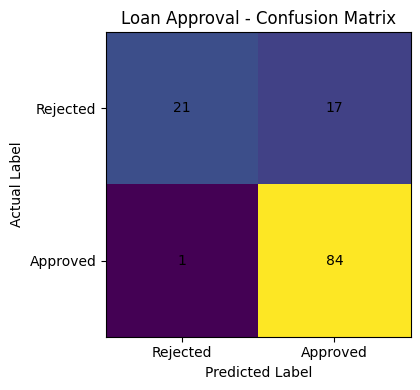

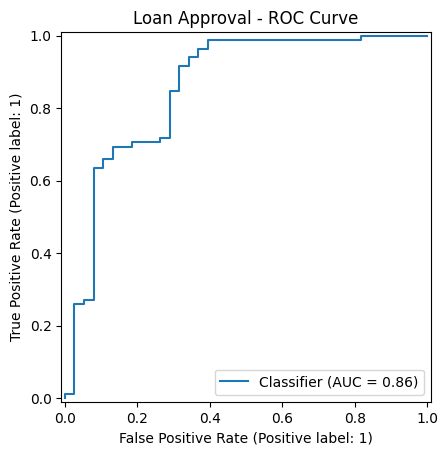

In [15]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay
)
import matplotlib.pyplot as plt

# Select the best model and its threshold
best_model = fitted_models[best_model_name]

# Predict probabilities on the test data
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

# Evaluate the model
print("Best Model:", best_model_name)
print("Selected Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test, test_predictions, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 3))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Loan Approval - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Rejected", "Approved"])
plt.yticks([0, 1], ["Rejected", "Approved"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("Loan Approval - ROC Curve")
plt.show()


In [16]:

print("BUSINESS INTERPRETATION")
print("-----------------------")

print(f"Best performing model: {best_model_name}")
print(f"Selected approval threshold: {best_threshold:.2f}")

print("\nRecommendations:")
print("1. Use the model to support, not replace, human loan decisions.")
print("2. Review false approvals and false rejections carefully.")
print("3. A lower threshold may approve more applicants but increase risk.")
print("4. A higher threshold may reduce risky approvals but reject more eligible applicants.")
print("5. Monitor model performance and check for unfair bias regularly.")
print("6. Test the model on new applicant data before real-world deployment.")

print("\nNote: The selected threshold maximizes F1-score on validation data.")
print("The final business threshold should also consider lending risk and fairness.")


BUSINESS INTERPRETATION
-----------------------
Best performing model: Logistic Regression
Selected approval threshold: 0.20

Recommendations:
1. Use the model to support, not replace, human loan decisions.
2. Review false approvals and false rejections carefully.
3. A lower threshold may approve more applicants but increase risk.
4. A higher threshold may reduce risky approvals but reject more eligible applicants.
5. Monitor model performance and check for unfair bias regularly.
6. Test the model on new applicant data before real-world deployment.

Note: The selected threshold maximizes F1-score on validation data.
The final business threshold should also consider lending risk and fairness.
